<a href="https://colab.research.google.com/github/pantojalvjonathan-ctrl/Sistema-mec-nico-de-un-robot-manipulador-planar-de-2-grados-de-libertad-/blob/main/PIA_Modelo_robot_de_2_grados_de_libertad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

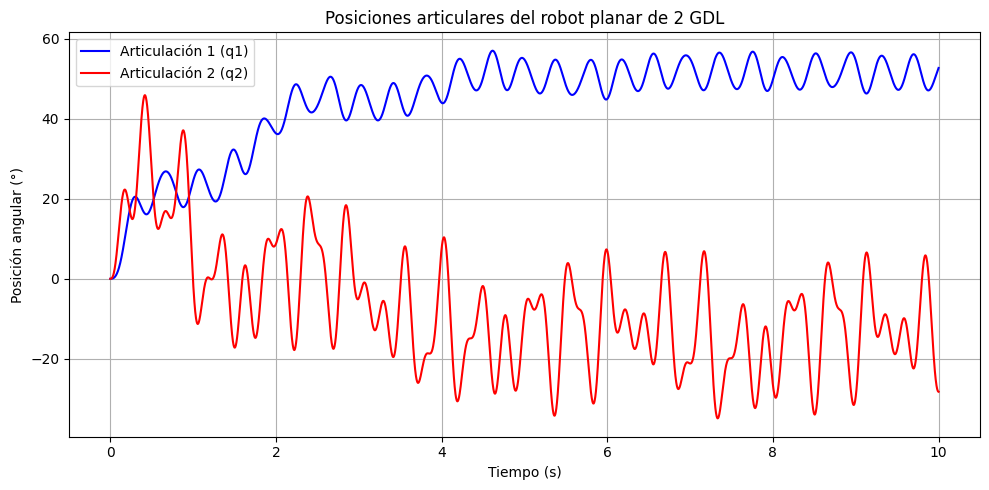

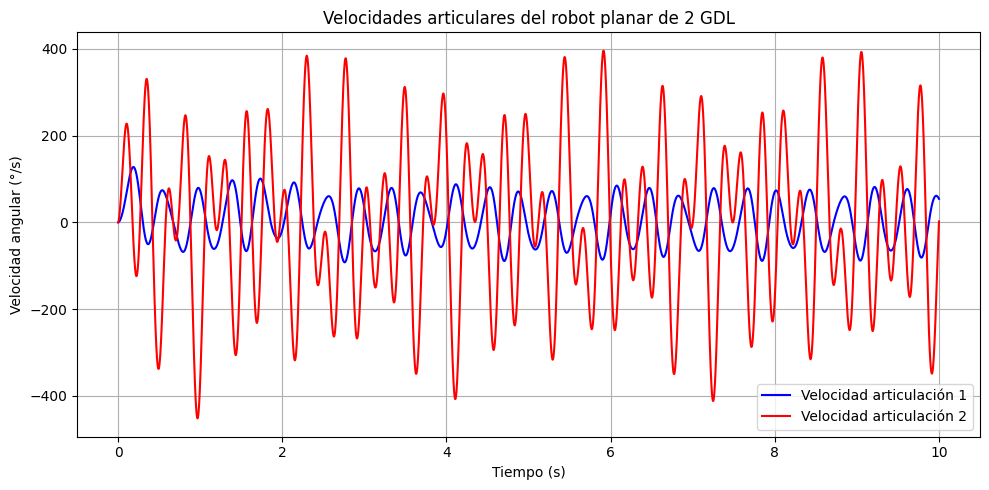

SIMULACIÓN DEL ROBOT PLANAR DE 2 GDL
-------------------------------------
Tiempo final: 10.00 s
Posición final q1: 52.7207 grados
Posición final q2: -28.2559 grados
Velocidad final qp1: 54.3398 grados/s
Velocidad final qp2: 2.1052 grados/s


In [2]:

# -----------------------------------------------------------------
# SIMULACIÓN DE UN ROBOT MANIPULADOR PLANAR DE 2 GDL
# Basado en el ejemplo 5.3 de Cortés (2020)
# Adaptación de MATLAB a Python para Google Colab
# -----------------------------------------------------------------

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# -----------------------------------------------------------------
# 1. DEFINICIÓN DEL MODELO DINÁMICO DEL ROBOT
# -----------------------------------------------------------------

def f(t, x):

    # -------------------------------------------------------------
    # 1.1 Vector de estados
    # -------------------------------------------------------------
    # x = [q1, q2, qp1, qp2]

    q = np.array([x[0], x[1]])       # Posiciones articulares
    qp = np.array([x[2], x[3]])      # Velocidades articulares

    # -------------------------------------------------------------
    # 1.2 Matriz de inercia M(q)
    # -------------------------------------------------------------

    M = np.array([
        [3.117 + 0.2*np.cos(q[1]), 0.108 + 0.1*np.cos(q[1])],
        [0.108 + 0.1*np.cos(q[1]), 0.108]
    ])

    # -------------------------------------------------------------
    # 1.3 Matriz de Coriolis y fuerzas centrípetas C(q,qp)
    # -------------------------------------------------------------

    C = np.array([
        [-0.2*np.sin(q[1])*qp[1],
         -0.1*np.sin(q[1])*qp[1]],

        [0.1*np.sin(q[1])*qp[0],
         0.0]
    ])

    # -------------------------------------------------------------
    # 1.4 Vector de pares gravitacionales g(q)
    # -------------------------------------------------------------

    gravedad = np.array([
        39.3*np.sin(q[0]) + 1.95*np.sin(q[0] + q[1]),
        1.95*np.sin(q[0] + q[1])
    ])

    # -------------------------------------------------------------
    # 1.5 Vector de fricción viscosa y de Coulomb
    # -------------------------------------------------------------

    friccion = np.array([
        1.86*qp[0] + 1.93*np.sign(qp[0]),
        0.16*qp[1] + 0.3*np.sign(qp[1])
    ])

    # -------------------------------------------------------------
    # 1.6 Pares ejercidos por los motores
    # -------------------------------------------------------------

    tau = np.array([
        (1 - np.exp(-0.8*t))*32.0
        + 56*np.sin(16*t + 0.1)
        + 12*np.sin(20*t + 0.15),

        (1 - np.exp(-1.8*t))*1.2
        + 8*np.sin(26*t + 0.08)
        + 2*np.sin(12*t + 0.34)
    ])

    # -------------------------------------------------------------
    # 1.7 Cálculo de las aceleraciones articulares
    # -------------------------------------------------------------
    # Ecuación dinámica:
    #
    # M(q)*qpp + C(q,qp)*qp + g(q) + f(qp) = tau
    #
    # Despejando:
    #
    # qpp = inv(M)*(tau - C*qp - g - f)
    #
    # Se utiliza solve en lugar de inv para mayor estabilidad
    # numérica.

    qpp = np.linalg.solve(
        M,
        tau - C @ qp - gravedad - friccion
    )

    # -------------------------------------------------------------
    # 1.8 Vector de salida
    # -------------------------------------------------------------

    dxdt = [
        qp[0],
        qp[1],
        qpp[0],
        qpp[1]
    ]

    return dxdt


# -----------------------------------------------------------------
# 2. PARÁMETROS DE SIMULACIÓN
# -----------------------------------------------------------------

ti = 0.0       # Tiempo inicial (s)
tf = 10.0      # Tiempo final (s)
h = 0.0025     # Incremento de tiempo (s)

# Vector de tiempo para evaluar la solución
ts = np.arange(ti, tf + h, h)

# -----------------------------------------------------------------
# 3. CONDICIONES INICIALES
# -----------------------------------------------------------------

q1_0 = 0.0     # Posición inicial articulación 1 (rad)
q2_0 = 0.0     # Posición inicial articulación 2 (rad)

qp1_0 = 0.0    # Velocidad inicial articulación 1 (rad/s)
qp2_0 = 0.0    # Velocidad inicial articulación 2 (rad/s)

# Vector de estados iniciales
x0 = [q1_0, q2_0, qp1_0, qp2_0]


# -----------------------------------------------------------------
# 4. RESOLUCIÓN DE LAS ECUACIONES DIFERENCIALES
# -----------------------------------------------------------------

sol = solve_ivp(
    f,
    [ti, tf],
    x0,
    t_eval=ts,
    method='RK45',
    rtol=1e-3,
    first_step=h,
    max_step=h
)

# Verificar que la simulación terminó correctamente
if not sol.success:
    raise RuntimeError(sol.message)

# Extraer resultados
t = sol.t

q1 = sol.y[0, :]
q2 = sol.y[1, :]

qp1 = sol.y[2, :]
qp2 = sol.y[3, :]


# -----------------------------------------------------------------
# 5. CONVERSIÓN DE RADIANES A GRADOS
# -----------------------------------------------------------------

q1_grados = np.rad2deg(q1)
q2_grados = np.rad2deg(q2)

qp1_grados = np.rad2deg(qp1)
qp2_grados = np.rad2deg(qp2)


# -----------------------------------------------------------------
# 6. GRÁFICA DE POSICIONES ARTICULARES
# -----------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(t, q1_grados, label='Articulación 1 (q1)', color='blue')
plt.plot(t, q2_grados, label='Articulación 2 (q2)', color='red')

plt.xlabel('Tiempo (s)')
plt.ylabel('Posición angular (°)')
plt.title('Posiciones articulares del robot planar de 2 GDL')

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------
# 7. GRÁFICA DE VELOCIDADES ARTICULARES
# -----------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(t, qp1_grados, label='Velocidad articulación 1', color='blue')
plt.plot(t, qp2_grados, label='Velocidad articulación 2', color='red')

plt.xlabel('Tiempo (s)')
plt.ylabel('Velocidad angular (°/s)')
plt.title('Velocidades articulares del robot planar de 2 GDL')

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------
# 8. RESULTADOS FINALES
# -----------------------------------------------------------------

print("SIMULACIÓN DEL ROBOT PLANAR DE 2 GDL")
print("-------------------------------------")

print(f"Tiempo final: {t[-1]:.2f} s")

print(f"Posición final q1: {q1_grados[-1]:.4f} grados")
print(f"Posición final q2: {q2_grados[-1]:.4f} grados")

print(f"Velocidad final qp1: {qp1_grados[-1]:.4f} grados/s")
print(f"Velocidad final qp2: {qp2_grados[-1]:.4f} grados/s")
